# Préparation des données pour Machine Learning

Ce notebook montre, étape par étape, comment préparer un jeu de données **avant** de créer un modèle de Machine Learning.

On utilise le dataset **Titanic** (disponible directement dans `seaborn`), donc pas besoin d'uploader un fichier : tout fonctionne directement dans Colab.

In [17]:
# Importer les librairies nécessaires
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

## Explication des librairies importées

- **pandas (pd)** : sert à manipuler les données sous forme de tableaux (comme Excel). On l'utilise pour lire, filtrer, transformer les colonnes du dataset.

- **numpy (np)** : librairie de calcul mathématique et scientifique. Elle est souvent utilisée en arrière-plan par les autres librairies pour faire des calculs rapides sur les nombres.

- **seaborn (sns)** : librairie qui permet de créer des graphiques (visualisation de données) et qui contient aussi des datasets prêts à l'emploi, comme le dataset Titanic utilisé ici.

- **matplotlib.pyplot (plt)** : librairie de base pour créer des graphiques en Python. Seaborn est construit par-dessus matplotlib.

- **train_test_split** (de sklearn.model_selection) : fonction qui permet de diviser les données en deux parties : une pour entraîner le modèle, une autre pour le tester.

- **StandardScaler** (de sklearn.preprocessing) : outil qui met toutes les variables numériques à la même échelle (normalisation), pour que le modèle ne favorise pas une variable juste parce qu'elle a de grandes valeurs (ex: fare vs age).

- **LabelEncoder** (de sklearn.preprocessing) : outil qui transforme des catégories en texte (ex: "male"/"female") en nombres (0/1), car un modèle de Machine Learning ne comprend que des chiffres.

## 1. Charger les données

In [18]:
df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [19]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Description des colonnes

- **survived** : la cible à prédire → `0` = n'a pas survécu, `1` = a survécu
- **pclass** : classe du billet → `1` = 1ère classe, `2` = 2ème, `3` = 3ème (lié au statut social)
- **sex** : sexe du passager (`male` ou `female`)
- **age** : âge du passager, en années
- **sibsp** : nombre de frères/sœurs ou de conjoint(e) à bord
- **parch** : nombre de parents/enfants à bord
- **fare** : prix payé pour le billet
- **embarked** : port d'embarquement → `S` = Southampton, `C` = Cherbourg, `Q` = Queenstown

## 2. Explorer les données

Avant de toucher aux données, il faut comprendre ce qu'on a : combien de lignes/colonnes, quels types de données, y a-t-il des valeurs bizarres...

In [20]:
df.shape

(891, 15)

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [22]:
print("Dimensions :", df.shape)
df.info()

Dimensions : (891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


### Explication du code
- `df.shape` : renvoie (nombre de lignes, nombre de colonnes) → la taille du dataset en un coup d'œil.
- `df.info()` : affiche, pour chaque colonne, son nom, le nombre de valeurs non vides (non-null) et son type (`int64`, `float64`, `object`...). Utile pour repérer les colonnes avec des valeurs manquantes ou du texte.

In [23]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Explication du code
`df.describe()` calcule des statistiques de base pour les colonnes numériques :
- `count` : nombre de valeurs non vides
- `mean` : moyenne
- `std` : écart-type (dispersion des valeurs)
- `min` / `max` : valeur minimale / maximale
- `25%`, `50%`, `75%` : quartiles (le `50%` est la médiane)

Ça aide à repérer des valeurs aberrantes (ex : un âge négatif, un prix anormalement élevé).

## 3. Garder uniquement les colonnes utiles

Le dataset Titanic contient des colonnes redondantes (ex: `class` = même info que `pclass`). On garde seulement ce dont on a besoin.

In [24]:
df.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


In [25]:
df = df[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']]
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


### Explication du code
- `df = df[[...]]` : garde uniquement les colonnes utiles listées entre crochets, et remplace `df` par cette version réduite.
- `df.head()` : affiche les 5 premières lignes, pour vérifier visuellement que la sélection a bien fonctionné.

## 4. Vérifier les valeurs manquantes

Un modèle de Machine Learning ne peut pas fonctionner avec des cases vides (NaN).

In [26]:
df.isnull()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
886,False,False,False,False,False,False,False,False
887,False,False,False,False,False,False,False,False
888,False,False,False,True,False,False,False,False
889,False,False,False,False,False,False,False,False


In [27]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2


### Explication du code
- `df.isnull()` : renvoie un tableau de même taille que `df`, rempli de `True`/`False` selon que chaque case est vide (NaN) ou non.
- `.sum()` : additionne les `True` (comptés comme 1) colonne par colonne → donne le nombre de valeurs manquantes par colonne.

## 5. Traiter les valeurs manquantes

- `age` (numérique) → on remplace par la **médiane**
- `embarked` (catégorielle) → on remplace par la valeur la plus fréquente (**mode**)

In [28]:
df['age'].median()

28.0

In [29]:
df['embarked'].mode()

,embarked
0,S


In [30]:
df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

In [31]:

df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0


### Explication du code
- `df['age'].median()` : calcule la valeur médiane de la colonne `age` (valeur du milieu une fois les âges triés).
- `.fillna(...)` : remplace toutes les valeurs manquantes (`NaN`) de la colonne par la valeur donnée.
- Même logique pour `embarked`, mais avec `.mode()[0]` : le mode est la valeur la plus fréquente ; `[0]` permet de prendre la première en cas d'égalité.
- La dernière ligne réaffiche `df.isnull().sum()` pour vérifier qu'il n'y a plus de valeurs manquantes.

## 6. Encoder les variables catégorielles

Un modèle de Machine Learning a besoin de **nombres**, pas de texte. On transforme donc les colonnes texte en nombres.

In [32]:
data= ["machine","deep","machine","IA"]

In [33]:
encoder = LabelEncoder()
data=encoder.fit_transform(data)

In [34]:
data

array([2, 1, 2, 0])

In [35]:
le_sex = LabelEncoder()

In [36]:
df['sex']

,sex
0,male
1,female
2,female
3,female
4,male
...,...
886,male
887,female
888,female
889,male


In [37]:
le_sex = LabelEncoder()
df['sex'] = le_sex.fit_transform(df['sex'])

In [38]:
df['sex']

,sex
0,1
1,0
2,0
3,0
4,1
...,...
886,1
887,0
888,0
889,1


In [39]:
# sex : male/female -> 0/1
le_sex = LabelEncoder()
df['sex'] = le_sex.fit_transform(df['sex'])

# embarked : plusieurs catégories -> one-hot encoding
df = pd.get_dummies(df, columns=['embarked'], drop_first=True)

df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked_Q,embarked_S
0,0,3,1,22.0,1,0,7.2500,False,True
1,1,1,0,38.0,1,0,71.2833,False,False
2,1,3,0,26.0,0,0,7.9250,False,True
3,1,1,0,35.0,1,0,53.1000,False,True
4,0,3,1,35.0,0,0,8.0500,False,True


### Explication du code
- `LabelEncoder()` crée un outil qui convertit du texte en nombres.
- `.fit_transform(df['sex'])` : apprend les catégories présentes (`male`, `female`) et les remplace directement par des chiffres (0 et 1).
- `pd.get_dummies(df, columns=['embarked'], drop_first=True)` : transforme `embarked` en plusieurs colonnes binaires (une par catégorie), avec `0` ou `1`. `drop_first=True` supprime une colonne redondante (si on connaît les deux autres, on déduit la troisième).
- `df.head()` : affiche les 5 premières lignes pour vérifier le résultat.

## 7. Séparer les features (X) et la cible (y)

- `X` = les colonnes qui servent à prédire
- `y` = la colonne qu'on veut prédire (ici : `survived`)

In [40]:
X = df.drop('survived', axis=1)
y = df['survived']

In [41]:
X

,pclass,sex,age,sibsp,parch,fare,embarked_Q,embarked_S
0,3,1,22.0,1,0,7.2500,False,True
1,1,0,38.0,1,0,71.2833,False,False
2,3,0,26.0,0,0,7.9250,False,True
3,1,0,35.0,1,0,53.1000,False,True
4,3,1,35.0,0,0,8.0500,False,True
...,...,...,...,...,...,...,...,...
886,2,1,27.0,0,0,13.0000,False,True
887,1,0,19.0,0,0,30.0000,False,True
888,3,0,28.0,1,2,23.4500,False,True
889,1,1,26.0,0,0,30.0000,False,False


In [42]:
y

,survived
0,0
1,1
2,1
3,1
4,0
...,...
886,0
887,1
888,0
889,1


### Explication du code
- `df.drop('survived', axis=1)` : crée `X` en retirant la colonne `survived` (on garde toutes les autres colonnes, celles qui servent à prédire). `axis=1` signifie qu'on supprime une colonne (et non une ligne).
- `df['survived']` : crée `y`, qui contient uniquement la colonne à prédire.

## 8. Diviser en ensemble d'entraînement et de test

On entraîne le modèle sur une partie des données (80%) et on le teste sur le reste (20%).

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Taille entraînement :", X_train.shape)
print("Taille test :", X_test.shape)

Taille entraînement : (712, 8)
Taille test : (179, 8)


### Explication du code
`train_test_split(X, y, test_size=0.2, random_state=42)` divise `X` et `y` en deux groupes :
- `test_size=0.2` : 20% des données vont dans le groupe de test, 80% dans le groupe d'entraînement.
- `random_state=42` : fixe le hasard pour que la division soit toujours la même à chaque exécution (résultats reproductibles).

Les tailles obtenues sont ensuite affichées avec `.shape`.

## 9. Normaliser les données numériques

On met toutes les valeurs numériques à la même échelle (utile pour beaucoup de modèles comme la régression logistique, KNN, SVM...).

In [44]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [45]:
X_train

,pclass,sex,age,sibsp,parch,fare,embarked_Q,embarked_S
331,1,1,45.5,0,0,28.5000,False,True
733,2,1,23.0,0,0,13.0000,False,True
382,3,1,32.0,0,0,7.9250,False,True
704,3,1,26.0,1,0,7.8542,False,True
813,3,0,6.0,4,2,31.2750,False,True
...,...,...,...,...,...,...,...,...
106,3,0,21.0,0,0,7.6500,False,True
270,1,1,28.0,0,0,31.0000,False,True
860,3,1,41.0,2,0,14.1083,False,True
435,1,0,14.0,1,2,120.0000,False,True


In [46]:
X_train_scaled

array([[-1.61413602,  0.7243102 ,  1.25364106, ..., -0.07868358,
        -0.30335547,  0.59248936],
       [-0.40055118,  0.7243102 , -0.47728355, ..., -0.37714494,
        -0.30335547,  0.59248936],
       [ 0.81303367,  0.7243102 ,  0.21508629, ..., -0.47486697,
        -0.30335547,  0.59248936],
       ...,
       [ 0.81303367,  0.7243102 ,  0.90745614, ..., -0.35580399,
        -0.30335547,  0.59248936],
       [-1.61413602, -1.38062393, -1.1696534 , ...,  1.68320121,
        -0.30335547,  0.59248936],
       [-1.61413602,  0.7243102 , -0.63114352, ...,  0.86074761,
        -0.30335547,  0.59248936]])

### Explication du code
- `StandardScaler()` crée un outil de normalisation.
- `.fit_transform(X_train)` : calcule la moyenne et l'écart-type de chaque colonne de `X_train`, puis transforme les données pour qu'elles aient une moyenne de 0 et un écart-type de 1.
- `.transform(X_test)` : applique la **même** transformation (calculée sur `X_train`) aux données de test, sans la recalculer — important pour ne pas laisser le modèle "voir" les données de test à l'avance.

## ✅ Données prêtes !

Tu as maintenant :
- `X_train_scaled`, `X_test_scaled` : les features, normalisées
- `y_train`, `y_test` : les valeurs à prédire

Tu peux les utiliser directement pour entraîner un modèle, par exemple :

```python
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_scaled, y_train)
print("Score :", model.score(X_test_scaled, y_test))
```

## Explication du modèle

- **LogisticRegression** : algorithme de classification qui calcule une probabilité (entre 0 et 1) qu'un passager ait survécu, puis applique un seuil pour décider de la catégorie finale.

- **model.fit(X_train_scaled, y_train)** : entraîne le modèle → il apprend la relation entre les variables (X_train_scaled) et le résultat réel (y_train).

- **model.score(X_test_scaled, y_test)** : évalue le modèle sur des données qu'il n'a jamais vues (X_test, y_test) et renvoie le pourcentage de bonnes prédictions (précision).

In [47]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_scaled, y_train)
print("Score :", model.score(X_test_scaled, y_test))

Score : 0.8100558659217877


In [48]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

On importe les outils nécessaires :
- `accuracy_score`, `precision_score`, `recall_score`, `f1_score` : pour calculer les métriques de performance
- `confusion_matrix` : pour construire la matrice de confusion
- `classification_report` : pour un résumé complet de toutes les métriques

In [49]:
y_pred = model.predict(X_test_scaled)

`model.predict(X_test_scaled)` : le modèle fait ses prédictions sur les données de test (qu'il n'a jamais vues pendant l'entraînement). Le résultat, `y_pred`, contient une prédiction (0 ou 1) pour chaque passager du test.

In [50]:
print("Accuracy  :", round(accuracy_score(y_test, y_pred), 3))
print("Précision :", round(precision_score(y_test, y_pred), 3))
print("Rappel    :", round(recall_score(y_test, y_pred), 3))
print("F1-score  :", round(f1_score(y_test, y_pred), 3))

Accuracy  : 0.81
Précision : 0.786
Rappel    : 0.743
F1-score  : 0.764


On compare `y_test` (les vraies réponses) à `y_pred` (les prédictions du modèle) pour calculer 4 métriques :
- **Accuracy** : pourcentage total de bonnes prédictions
- **Précision** : parmi les passagers prédits "survécu", combien ont vraiment survécu
- **Rappel** : parmi les passagers qui ont vraiment survécu, combien le modèle a-t-il retrouvés
- **F1-score** : moyenne équilibrée entre précision et rappel

In [51]:
print(classification_report(y_test, y_pred, target_names=["N'a pas survécu", "A survécu"]))

                 precision    recall  f1-score   support

N'a pas survécu       0.83      0.86      0.84       105
      A survécu       0.79      0.74      0.76        74

       accuracy                           0.81       179
      macro avg       0.81      0.80      0.80       179
   weighted avg       0.81      0.81      0.81       179



`classification_report(...)` affiche automatiquement toutes les métriques (précision, rappel, f1-score) séparément pour chaque classe ("A survécu" / "N'a pas survécu"), plus une moyenne globale.

In [52]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[90 15]
 [19 55]]



`confusion_matrix(y_test, y_pred)` construit un tableau 2x2 qui compare les vraies valeurs aux prédictions :
- Diagonale = bonnes prédictions
- Hors diagonale = erreurs (faux positifs / faux négatifs)

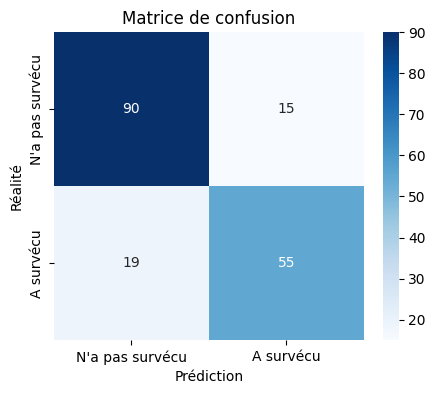

In [ ]:
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["N'a pas survécu", "A survécu"],
            yticklabels=["N'a pas survécu", "A survécu"])
plt.xlabel("Prédiction")
plt.ylabel("Réalité")
plt.title("Matrice de confusion")
plt.show()

`sns.heatmap(...)` dessine la matrice de confusion en couleur, avec les chiffres affichés dans chaque case (`annot=True`). Plus une case est foncée, plus le nombre est élevé. L'axe X montre ce que le modèle a prédit, l'axe Y montre la vraie réalité.

In [ ]:

# Exemple : un nouveau passager
nouveau_passager = pd.DataFrame({
    'pclass': [1],        # 1ère classe
    'sex': [1],            # 1 = male, 0 = female (encodé comme dans le training)
    'age': [25],
    'sibsp': [0],
    'parch': [0],
    'fare': [80],
    'embarked_Q': [0],
    'embarked_S': [1]      # a embarqué à Southampton
})

# Important : appliquer la MÊME normalisation que sur les données d'entraînement
nouveau_passager_scaled = scaler.transform(nouveau_passager)

# Prédiction
prediction = model.predict(nouveau_passager_scaled)
probabilite = model.predict_proba(nouveau_passager_scaled)

print("Prédiction :", "A survécu ✅" if prediction[0] == 1 else "N'a pas survécu ❌")
print("Probabilité de survie :", round(probabilite[0][1] * 100, 2), "%")

Prédiction : A survécu ✅
Probabilité de survie : 50.59 %


- `prediction[0]` : on prend le premier (et seul) élément du tableau de prédictions, puisqu'on n'a testé qu'un seul passager.
- `"A survécu ✅" if prediction[0] == 1 else "N'a pas survécu ❌"` : traduit le chiffre (0 ou 1) en texte lisible.
- `probabilite[0][1]` : récupère la probabilité de survie (classe `1`) pour ce passager, et on la convertit en pourcentage avec `* 100`.